# Семинар 7: Понижение размерности

**Цели:**
1. Понять, как работает **PCA** (сжатие, визуализация, реконструкция).
2. Увидеть разницу между линейными (PCA) и нелинейными методами (**t-SNE, UMAP, Isomap**).
3. Познакомиться с **NMF** на примере изображений лиц (поиск «базисных» частей).
4. Сравнить **PCA** и **LDA** (обучение с учителем) на табличных данных.
5. Обсудить типичные ошибки (масштабирование, утечка данных, интерпретация t-SNE).

In [1]:
# Установка UMAP (в Colab или локально)
%pip install umap-learn -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits, make_swiss_roll, load_wine, fetch_olivetti_faces
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, NMF
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.manifold import TSNE, Isomap, LocallyLinearEmbedding
import umap

plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

## Часть 1. PCA: Сжатие и Реконструкция (Датасет Digits)

Возьмем классический датасет рукописных цифр (8x8 пикселей = 64 признака). Посмотрим, сколько компонент нужно, чтобы описать данные.

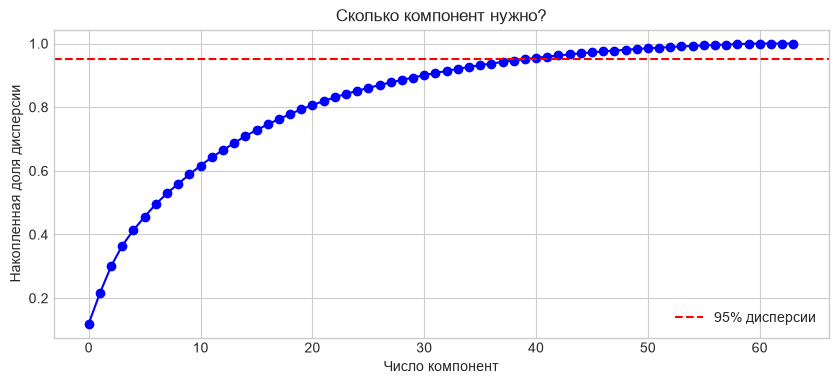

Для 95% дисперсии нужно 40 компонент(ы) из 64.


In [3]:
digits = load_digits()
X_digits = digits.data
y_digits = digits.target

# Масштабирование (обязательно для PCA!)
X_digits_scaled = StandardScaler().fit_transform(X_digits)

# PCA
pca = PCA(random_state=42)
X_pca = pca.fit_transform(X_digits_scaled)

# График каменистой осыпи (Scree Plot)
plt.figure(figsize=(10, 4))
plt.plot(np.cumsum(pca.explained_variance_ratio_), 'bo-')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% дисперсии')
plt.xlabel('Число компонент')
plt.ylabel('Накопленная доля дисперсии')
plt.title('Сколько компонент нужно?')
plt.legend()
plt.grid(True)
plt.show()

print(f"Для 95% дисперсии нужно {np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.95) + 1} компонент(ы) из 64.")

### Визуализация и Реконструкция
Посмотрим на цифры в 2D пространстве и попробуем восстановить их из разного числа компонент.

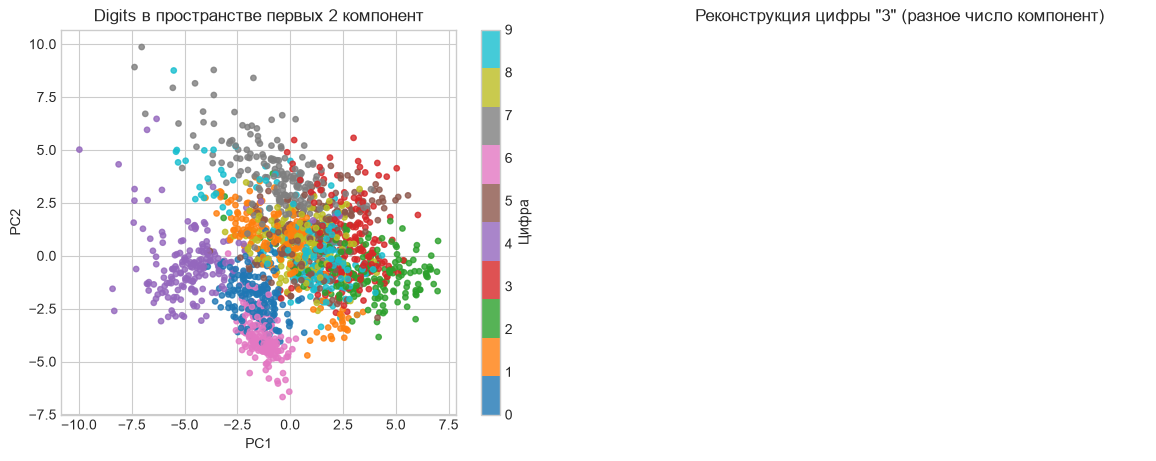

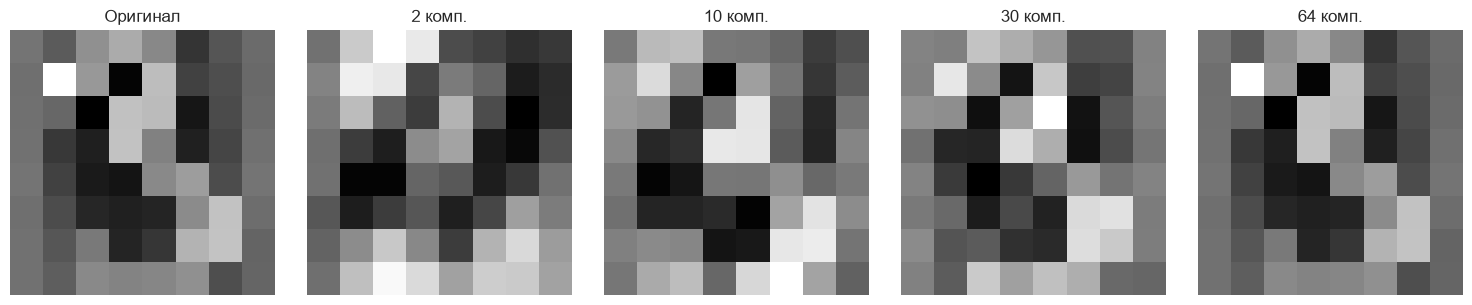

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Визуализация в 2D
scatter = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_digits, cmap='tab10', s=15, alpha=0.8)
axes[0].set_title('Digits в пространстве первых 2 компонент')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
plt.colorbar(scatter, ax=axes[0], label='Цифра')

# 2. Реконструкция
# Обучаем PCA с разным числом компонент и делаем inverse_transform
n_components_list = [2, 10, 30, 64]
axes[1].axis('off')
axes[1].set_title('Реконструкция цифры "3" (разное число компонент)')

idx = np.where(y_digits == 3)[0][0] # берем первую тройку
original = X_digits_scaled[idx].reshape(8, 8)

reconstructions = []
for n in n_components_list:
    pca_n = PCA(n_components=n, random_state=42)
    X_trans = pca_n.fit_transform(X_digits_scaled)
    X_recon = pca_n.inverse_transform(X_trans)
    reconstructions.append(X_recon[idx].reshape(8, 8))

# Отрисовка
fig2, axes2 = plt.subplots(1, 5, figsize=(15, 3))
axes2[0].imshow(original, cmap='gray'); axes2[0].set_title('Оригинал'); axes2[0].axis('off')
for i, (n, rec) in enumerate(zip(n_components_list, reconstructions)):
    axes2[i+1].imshow(rec, cmap='gray')
    axes2[i+1].set_title(f'{n} комп.')
    axes2[i+1].axis('off')
plt.tight_layout()
plt.show()

**Обсуждение:**
* Даже 10 компонент из 64 достаточно, чтобы разобрать цифру.
* В 2D мы видим, что некоторые классы (например, 1 и 7) пересекаются. PCA максимизирует **общую дисперсию**, но не обязательно разделяет классы (он не знает про `y`).

## Часть 2. Нелинейные многообразия: «Швейцарский рулет» (Swiss Roll)
PCA — линейный метод. Если данные лежат на нелинейном многообразии (свернуты в рулет), PCA просто «сплющит» его. Покажем это и спасем ситуацию методами Isomap, LLE и t-SNE.

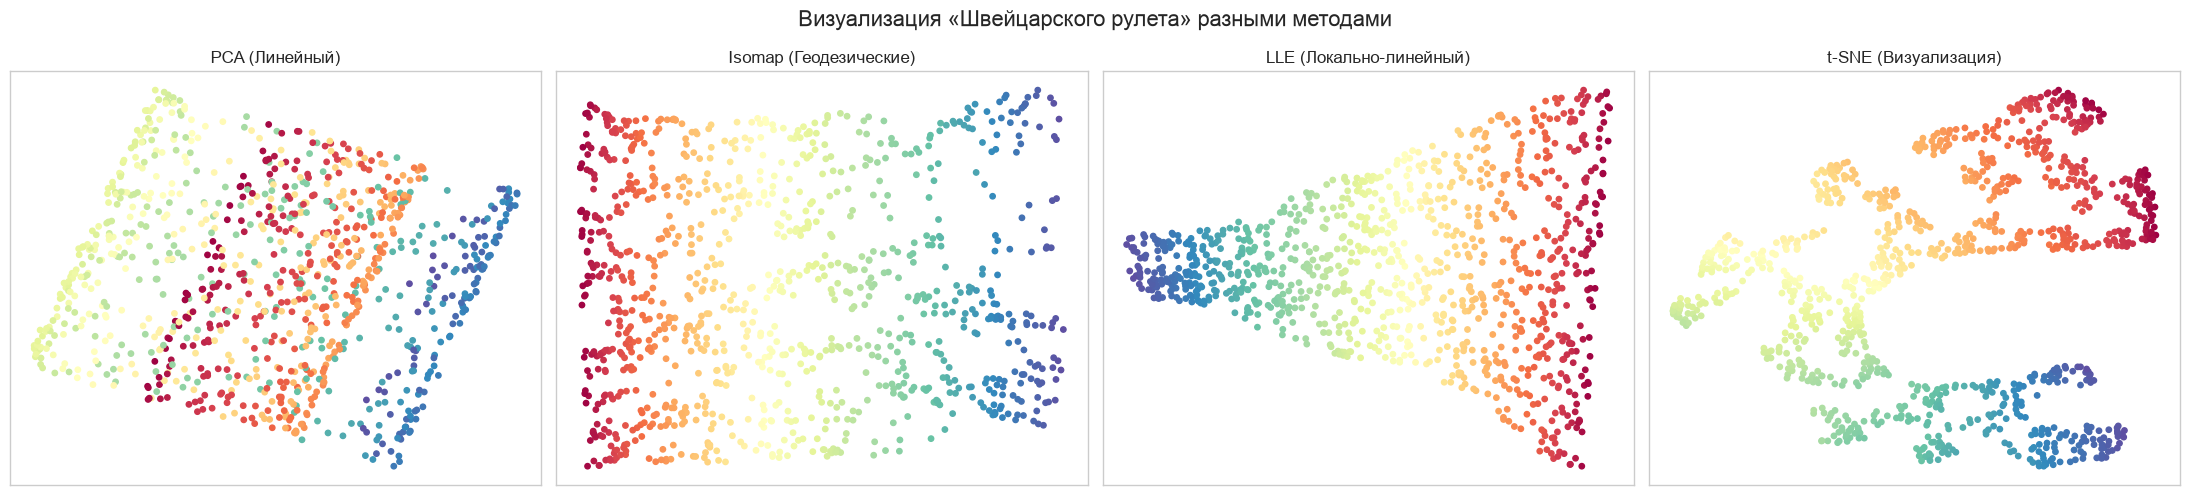

In [15]:
# Генерируем данные
X_swiss, color_swiss = make_swiss_roll(n_samples=1000, noise=0.1, random_state=42)
X_swiss_scaled = StandardScaler().fit_transform(X_swiss)

# Применяем методы
methods = {
    'PCA (Линейный)': PCA(n_components=2, random_state=42),
    'Isomap (Геодезические)': Isomap(n_components=2, n_neighbors=10),
    'LLE (Локально-линейный)': LocallyLinearEmbedding(n_components=2, n_neighbors=10, random_state=42),
    't-SNE (Визуализация)': TSNE(n_components=2, perplexity=30, random_state=42)
}

fig, axes = plt.subplots(1, 4, figsize=(22, 5))

for ax, (name, model) in zip(axes, methods.items()):
    X_emb = model.fit_transform(X_swiss_scaled)
    ax.scatter(X_emb[:, 0], X_emb[:, 1], c=color_swiss, cmap='Spectral', s=15)
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('Визуализация «Швейцарского рулета» разными методами', fontsize=16)
plt.tight_layout()
plt.show()

**Обсуждение:**
* **PCA** просто сплющил рулет, смешав цвета.
* **Isomap** и **LLE** попытались «развернуть» его, сохраняя геодезические расстояния (расстояния вдоль поверхности).
* **t-SNE** отлично разделил локальные соседства (точки одного цвета рядом), но глобальные расстояния (порядок цветов) могут быть искажены.

## Часть 3. t-SNE vs UMAP на цифрах
Сравним современные методы визуализации на датасете Digits. UMAP работает быстрее и умеет проецировать новые точки (transform), в отличие от t-SNE.

/opt/anaconda3/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


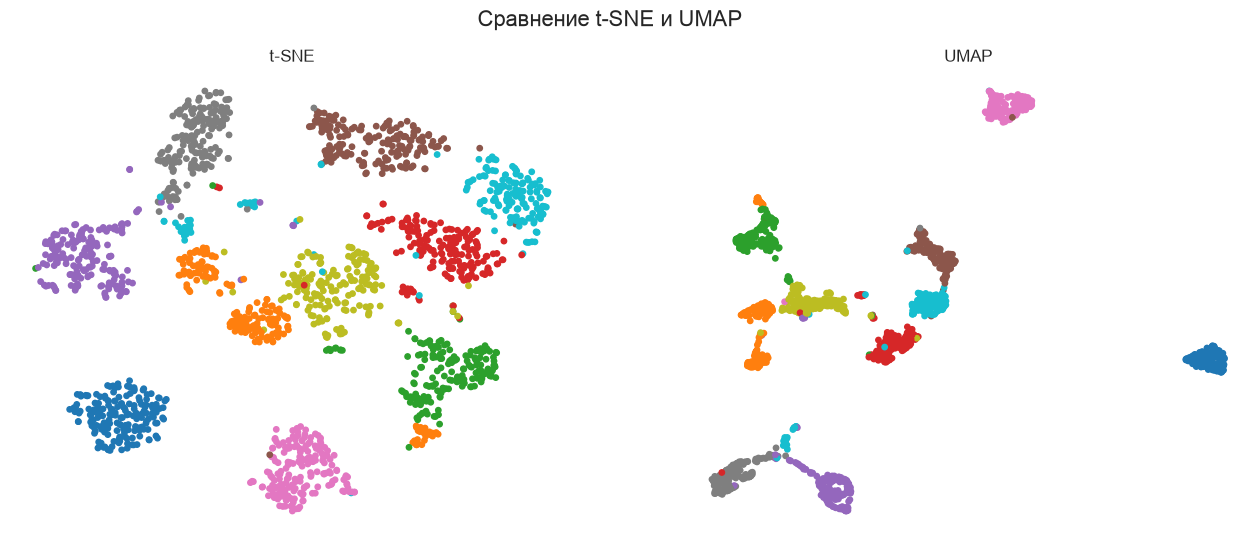

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_digits_scaled)
axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_digits, cmap='tab10', s=15)
axes[0].set_title('t-SNE')
axes[0].axis('off')

# UMAP
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42)
X_umap = reducer.fit_transform(X_digits_scaled)
axes[1].scatter(X_umap[:, 0], X_umap[:, 1], c=y_digits, cmap='tab10', s=15)
axes[1].set_title('UMAP')
axes[1].axis('off')

plt.suptitle('Сравнение t-SNE и UMAP', fontsize=16)
plt.show()

**Проверка `transform` в UMAP:**
Если бы к нам пришла новая цифра, мы не смогли бы ее спроецировать через t-SNE (нужно переобучать всё заново). А UMAP может это сделать:

In [7]:
# Берем 5 новых точек (которых не было при обучении, просто срез)
X_new = X_digits_scaled[:5]
X_new_umap = reducer.transform(X_new)
print(f"Форма новых точек после transform: {X_new_umap.shape}")
print("UMAP успешно спроецировал новые данные в 2D!")

Форма новых точек после transform: (5, 2)
UMAP успешно спроецировал новые данные в 2D!


## Часть 4. NMF (Неотрицательная матричная факторизация) на лицах
NMF требует, чтобы данные были неотрицательными (например, яркость пикселей > 0). В отличие от PCA (который ищет целые «лица-призраки»), NMF ищет **аддитивные части** (нос, глаза, брови).

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /Users/evakhromeeva/scikit_learn_data


/opt/anaconda3/lib/python3.14/site-packages/sklearn/decomposition/_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


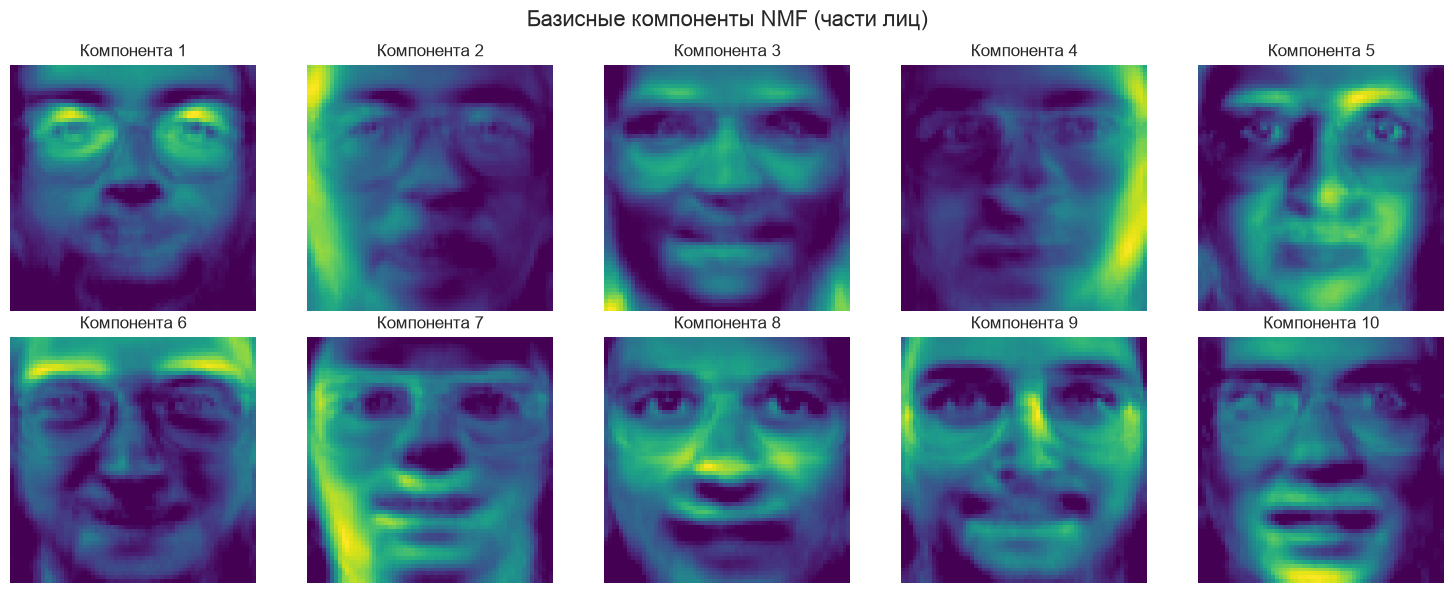

In [8]:
# Загружаем лица (64x64 = 4096 признаков, 400 изображений)
faces = fetch_olivetti_faces(shuffle=True, random_state=42)
X_faces = faces.data

# NMF
n_components = 10
nmf = NMF(n_components=n_components, init='nndsvda', random_state=42)
W = nmf.fit_transform(X_faces) # Веса для каждого лица
H = nmf.components_           # Сами базисные компоненты (темы)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(H[i].reshape(64, 64), cmap='viridis')
    ax.set_title(f'Компонента {i+1}')
    ax.axis('off')
plt.suptitle('Базисные компоненты NMF (части лиц)', fontsize=16)
plt.tight_layout()
plt.show()

**Обсуждение:**
Посмотрите на компоненты. NMF выучил «глаза», «бороды», «очки». Если сложить их с определенными весами (`W`), получится конкретное лицо. Это называется аддитивной декомпозицией. PCA бы дал компоненты, где есть и положительные, и отрицательные значения (что визуально выглядит как шум).

## Часть 5. Обучение с учителем: PCA vs LDA
Иногда нам важно не просто сжать данные, а **разделить классы**. LDA использует метки `y` для максимизации расстояния между классами. Проверим на датасете Wine.

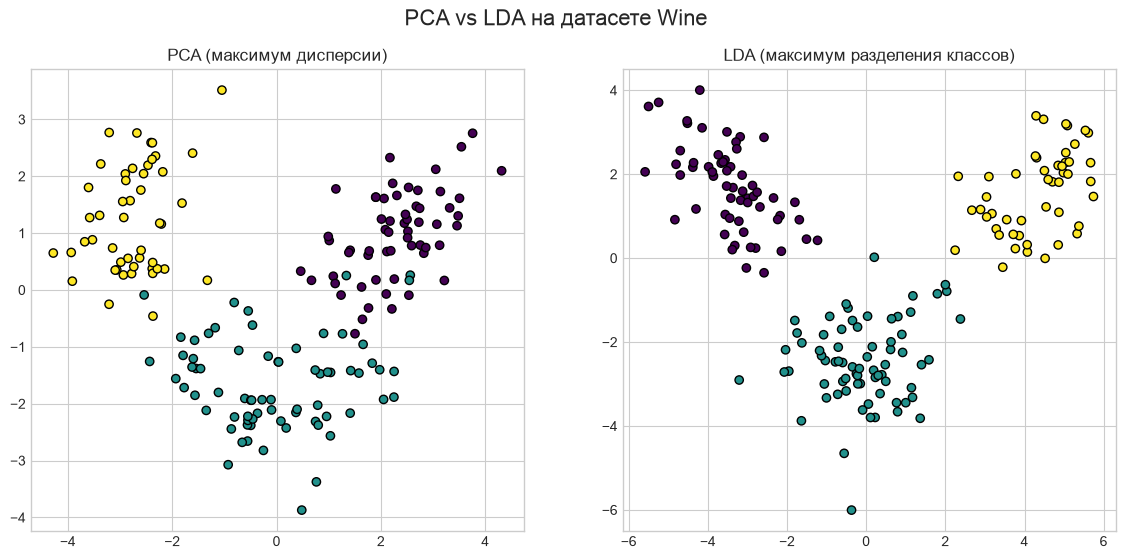

In [9]:
wine = load_wine()
X_wine = StandardScaler().fit_transform(wine.data)
y_wine = wine.target

# PCA 2D
pca_wine = PCA(n_components=2, random_state=42)
X_pca_wine = pca_wine.fit_transform(X_wine)

# LDA 2D
lda_wine = LDA(n_components=2)
X_lda_wine = lda_wine.fit_transform(X_wine, y_wine)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(X_pca_wine[:, 0], X_pca_wine[:, 1], c=y_wine, cmap='viridis', edgecolor='k')
axes[0].set_title('PCA (максимум дисперсии)')

axes[1].scatter(X_lda_wine[:, 0], X_lda_wine[:, 1], c=y_wine, cmap='viridis', edgecolor='k')
axes[1].set_title('LDA (максимум разделения классов)')

plt.suptitle('PCA vs LDA на датасете Wine', fontsize=16)
plt.show()

**Обсуждение:**
* PCA (левый график) сохраняет общую структуру, но классы немного перемешаны.
* LDA (правый график) «растянул» данные так, чтобы три сорта вина были максимально далеко друг от друга.
* **Важно:** LDA использует `y`. Если применять LDA до разделения на train/test, это приведет к **утечке данных (data leakage)**! Применять только внутри `Pipeline` после `train_test_split`.